# Retail Sales EDA — Superstore

**Goal:** find where this retailer makes and loses money, and what to do about it.

**Dataset:** Superstore Sales (US orders, 2015–2018), `data/raw/superstore.csv`.

**Questions**
1. How are sales and profit trending, and is there seasonality?
2. Which categories, products, regions and segments drive profit — and which lose money?
3. What does discounting do to profitability?
4. How concentrated is revenue among customers?

## 1. Setup & load

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (9, 4)
pd.options.display.float_format = "{:,.2f}".format

raw = pd.read_csv("../data/raw/superstore.csv")
print(raw.shape)
raw.head()

(10800, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,"42,420.00",South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.96,2.00,0.00,41.91
1,2,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,"42,420.00",South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.94,3.00,0.00,219.58
2,3,CA-2017-138688,6/12/2017,6/16/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,"90,036.00",West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.62,2.00,0.00,6.87
3,4,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,"33,311.00",South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.58,5.00,0.45,-383.03
4,5,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,"33,311.00",South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.37,2.00,0.20,2.52


## 2. Clean
The CSV has the *Orders* sheet followed by extra rows from other worksheets (Returns / People),
so many rows are blank in the order columns. Check, then keep only real orders.

In [2]:
print("Rows with no Sales value:", raw["Sales"].isna().sum())
df = raw.dropna(subset=["Sales"]).copy()

df["Order Date"] = pd.to_datetime(df["Order Date"], format="%m/%d/%Y")
df["Ship Date"] = pd.to_datetime(df["Ship Date"], format="%m/%d/%Y")

print("Clean shape:", df.shape)
print("Duplicate rows:", df.duplicated().sum())
print("Date range:", df["Order Date"].min().date(), "->", df["Order Date"].max().date())
df.isna().sum()[lambda s: s > 0]

Rows with no Sales value: 806
Clean shape: (9994, 21)
Duplicate rows: 0
Date range: 2015-01-03 -> 2018-12-30


Postal Code    11
dtype: int64

Only `Postal Code` has gaps (a handful of Vermont rows). We don't use it, so it is left as is.

In [3]:
df.describe().T[["count", "mean", "std", "min", "50%", "max"]]

,count,mean,std,min,50%,max
Order Date,9994,2017-04-30 05:17:08.056834,NaN,2015-01-03 00:00:00,2017-06-26 00:00:00,2018-12-30 00:00:00
Ship Date,9994,2017-05-04 04:17:20.304182,NaN,2015-01-07 00:00:00,2017-06-29 00:00:00,2019-01-05 00:00:00
Postal Code,"9,983.00","55,245.23","32,038.72","1,040.00","57,103.00","99,301.00"
Sales,"9,994.00",229.86,623.25,0.44,54.49,"22,638.48"
Quantity,"9,994.00",3.79,2.23,1.00,3.00,14.00
Discount,"9,994.00",0.16,0.21,0.00,0.20,0.80
Profit,"9,994.00",28.66,234.26,"-6,599.98",8.67,"8,399.98"


## 3. Feature engineering

In [4]:
df["year"] = df["Order Date"].dt.year
df["month"] = df["Order Date"].dt.month
df["month_start"] = df["Order Date"].dt.to_period("M").dt.to_timestamp()
df["profit_margin"] = df["Profit"] / df["Sales"]
df["ship_days"] = (df["Ship Date"] - df["Order Date"]).dt.days

total_sales, total_profit = df["Sales"].sum(), df["Profit"].sum()
print(f"Total sales : ${total_sales:,.0f}")
print(f"Total profit: ${total_profit:,.0f}  ({total_profit/total_sales:.1%} margin)")
print(f"Orders: {df['Order ID'].nunique():,} | Customers: {df['Customer ID'].nunique():,}")

Total sales : $2,297,201
Total profit: $286,397  (12.5% margin)
Orders: 5,009 | Customers: 793


## 4. Trend & seasonality

In [5]:
yearly = df.groupby("year")[["Sales", "Profit"]].sum()
yearly["margin"] = yearly["Profit"] / yearly["Sales"]
yearly["sales_growth"] = yearly["Sales"].pct_change()
yearly

,Sales,Profit,margin,sales_growth
year,,,,
2015,"484,247.50","49,543.97",0.10,NaN
2016,"470,532.51","61,618.60",0.13,-0.03
2017,"609,205.60","81,795.17",0.13,0.29
2018,"733,215.26","93,439.27",0.13,0.20


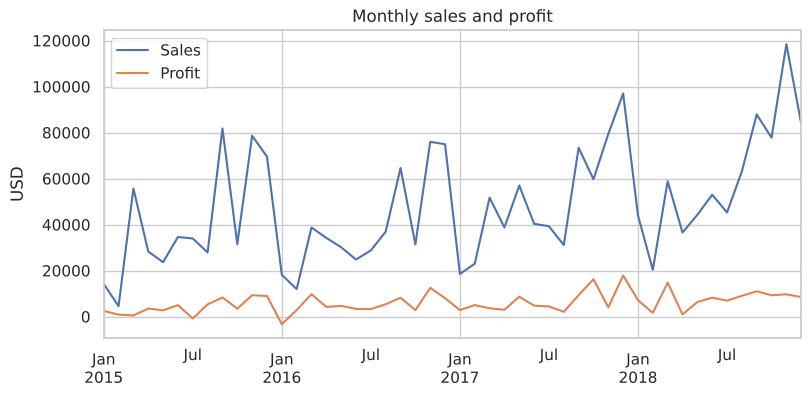

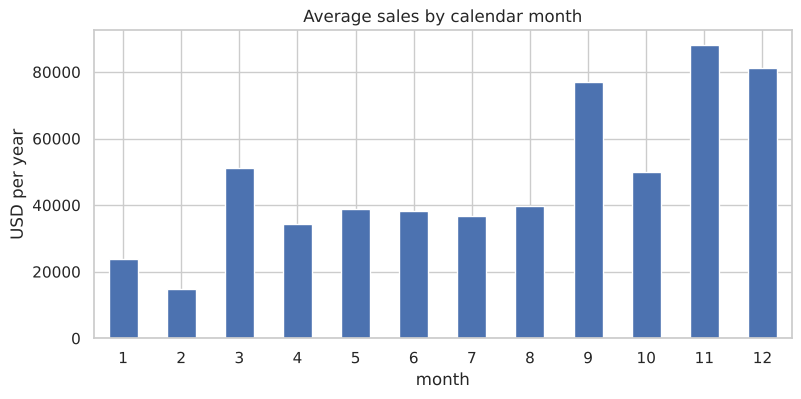

In [6]:
monthly = df.groupby("month_start")[["Sales", "Profit"]].sum()
ax = monthly.plot(title="Monthly sales and profit")
ax.set_ylabel("USD"); ax.set_xlabel("")
plt.show()

seasonal = df.groupby("month")["Sales"].sum() / df["year"].nunique()
seasonal.plot.bar(title="Average sales by calendar month", rot=0)
plt.ylabel("USD per year"); plt.show()

**Finding:** sales grew every year after a small dip in 2016 (2018 sales ≈ 1.5× 2015), and margin stayed
around 10–13%. Sales are strongly seasonal: **November and December are the peak**, with a second bump in
September and a trough in January–February.

## 5. Category & product performance

,Sales,Profit,margin
Category,,,
Technology,"836,154.03","145,454.95",0.17
Office Supplies,"719,047.03","122,490.80",0.17
Furniture,"741,999.80","18,451.27",0.02


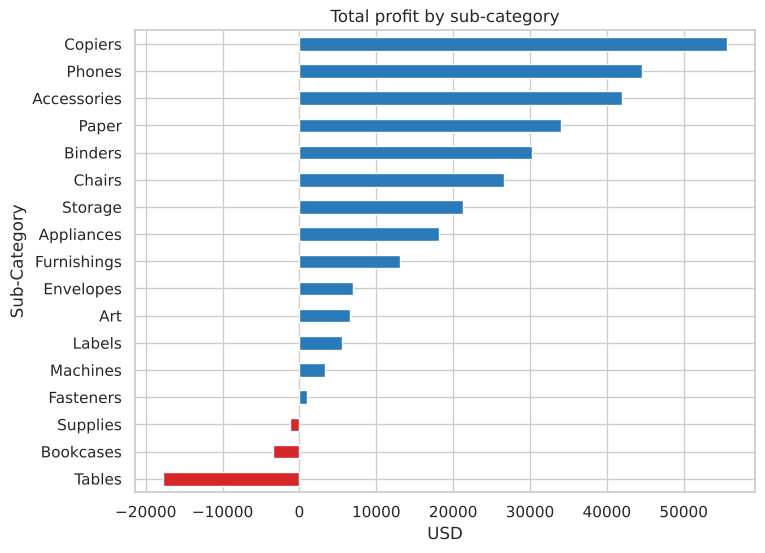

In [7]:
cat = df.groupby("Category")[["Sales", "Profit"]].sum()
cat["margin"] = cat["Profit"] / cat["Sales"]
display(cat.sort_values("Profit", ascending=False))

sub = df.groupby("Sub-Category")[["Sales", "Profit"]].sum().sort_values("Profit")
colors = ["#d62728" if p < 0 else "#2a7ab9" for p in sub["Profit"]]
sub["Profit"].plot.barh(color=colors, figsize=(8, 6), title="Total profit by sub-category")
plt.xlabel("USD"); plt.show()

**Finding:** Furniture is the problem category — ~$742K in sales but only ~$18K profit (2.5% margin).
Three sub-categories **lose money**: **Tables (−$17.7K)**, Bookcases and Supplies. Copiers, Phones and
Accessories are the most profitable.

## 6. Region, state & segment

,Sales,Profit,margin
Region,,,
West,"725,457.82","108,418.45",0.15
East,"678,781.24","91,522.78",0.13
South,"391,721.91","46,749.43",0.12
Central,"501,239.89","39,706.36",0.08


,Sales,Profit,margin
Segment,,,
Consumer,"1,161,401.34","134,119.21",0.12
Corporate,"706,146.37","91,979.13",0.13
Home Office,"429,653.15","60,298.68",0.14


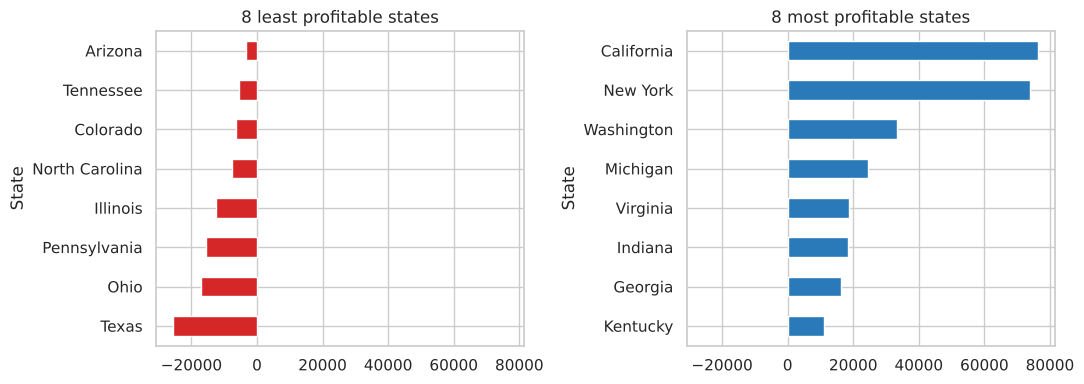

In [8]:
reg = df.groupby("Region")[["Sales", "Profit"]].sum()
reg["margin"] = reg["Profit"] / reg["Sales"]
display(reg.sort_values("Profit", ascending=False))

seg = df.groupby("Segment")[["Sales", "Profit"]].sum()
seg["margin"] = seg["Profit"] / seg["Sales"]
display(seg)

state = df.groupby("State")["Profit"].sum().sort_values()
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharex=True)
state.head(8).plot.barh(ax=axes[0], color="#d62728", title="8 least profitable states")
state.tail(8).plot.barh(ax=axes[1], color="#2a7ab9", title="8 most profitable states")
plt.tight_layout(); plt.show()

**Finding:** West and East generate most of the profit; **Central has the weakest margin (~7.9%)**.
Texas (−$25.7K), Ohio and Pennsylvania are the biggest loss-making states — worth checking whether
heavy discounting or Furniture/Tables mix is behind it. Consumer is the largest segment by sales.

## 7. Discounts vs profitability

,orders,avg_margin,total_profit
Discount,,,
0.00,4798,0.34,"320,987.60"
0.10,94,0.16,"9,029.18"
0.15,52,0.03,"1,418.99"
0.20,3657,0.18,"90,337.31"
0.30,227,-0.12,"-10,369.28"
0.32,27,-0.17,"-2,391.14"
0.40,206,-0.22,"-23,057.05"
0.45,11,-0.45,"-2,493.11"
0.50,66,-0.55,"-20,506.43"


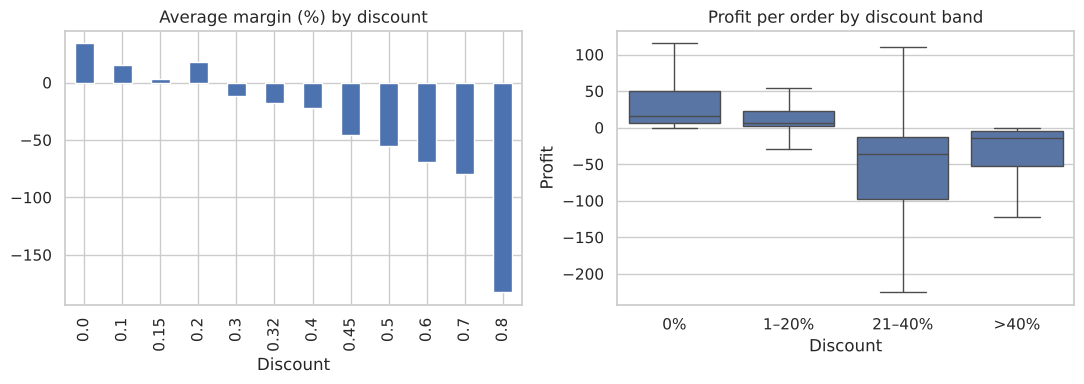

In [9]:
disc = df.groupby("Discount").agg(orders=("Sales", "size"),
                                  avg_margin=("profit_margin", "mean"),
                                  total_profit=("Profit", "sum"))
display(disc)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
disc["avg_margin"].mul(100).plot.bar(ax=axes[0], title="Average margin (%) by discount")
sns.boxplot(data=df, x=pd.cut(df["Discount"], [-.01, 0, .2, .4, 1],
            labels=["0%", "1–20%", "21–40%", ">40%"]), y="Profit", ax=axes[1], showfliers=False)
axes[1].set_title("Profit per order by discount band"); axes[1].set_xlabel("Discount")
plt.tight_layout(); plt.show()

**Finding — the key insight:** profit turns negative once discounts reach **30%**. Orders at 0% discount
earn ~34% margin and 20% still earn ~18%, but 30%+ orders lose money and 70–80% discounts average a
−80% to −180% margin. Those deep-discount orders cost more than $100K in profit.

In [10]:
deep = df[df["Discount"] >= 0.3]
print(f"{len(deep):,} orders ({len(deep)/len(df):.0%}) have discount >= 30%; "
      f"they lost ${-deep['Profit'].sum():,.0f} in total.")
print("Profit if those orders had broken even:", f"${total_profit - deep['Profit'].sum():,.0f}",
      f"vs actual ${total_profit:,.0f}")

1,393 orders (14%) have discount >= 30%; they lost $135,376 in total.
Profit if those orders had broken even: $421,773 vs actual $286,397


## 8. Correlations & outliers

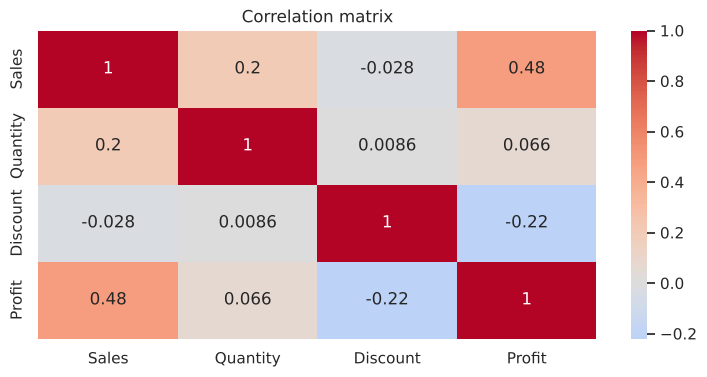

IQR upper fence: $499 -> 1,167 high-value orders (12%) carry 64% of sales


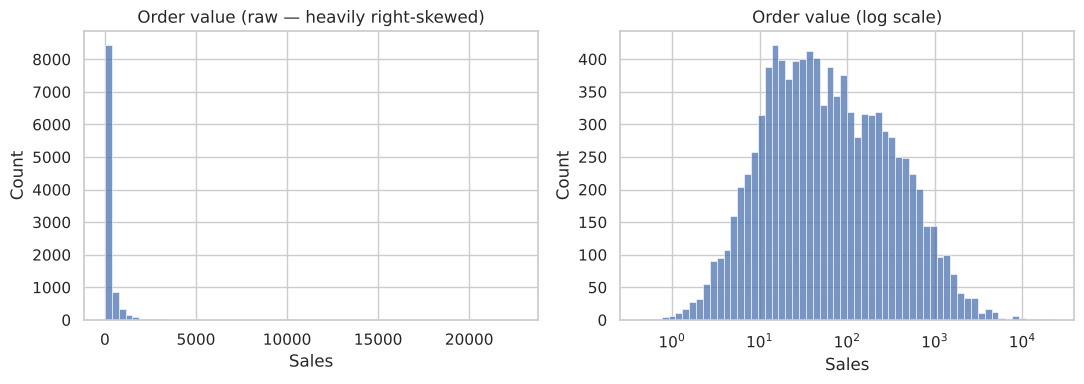

In [11]:
sns.heatmap(df[["Sales", "Quantity", "Discount", "Profit"]].corr(), annot=True, cmap="coolwarm", center=0)
plt.title("Correlation matrix"); plt.show()

q1, q3 = df["Sales"].quantile([.25, .75])
upper = q3 + 1.5 * (q3 - q1)
print(f"IQR upper fence: ${upper:,.0f} -> {(df['Sales'] > upper).sum():,} high-value orders "
      f"({(df['Sales'] > upper).mean():.0%}) carry {df.loc[df['Sales'] > upper, 'Sales'].sum()/total_sales:.0%} of sales")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(df["Sales"], bins=60, ax=axes[0]); axes[0].set_title("Order value (raw — heavily right-skewed)")
sns.histplot(df["Sales"], bins=60, log_scale=True, ax=axes[1]); axes[1].set_title("Order value (log scale)")
plt.tight_layout(); plt.show()

**Finding:** Discount is negatively correlated with profit (−0.22) while Quantity barely matters.
Order values are very right-skewed: a small share of large orders drive a big chunk of revenue,
so use medians (not means) when describing a "typical" order.

## 9. Customers

793 customers; top 20% generate 48% of sales
Customers with 2+ orders: 98%


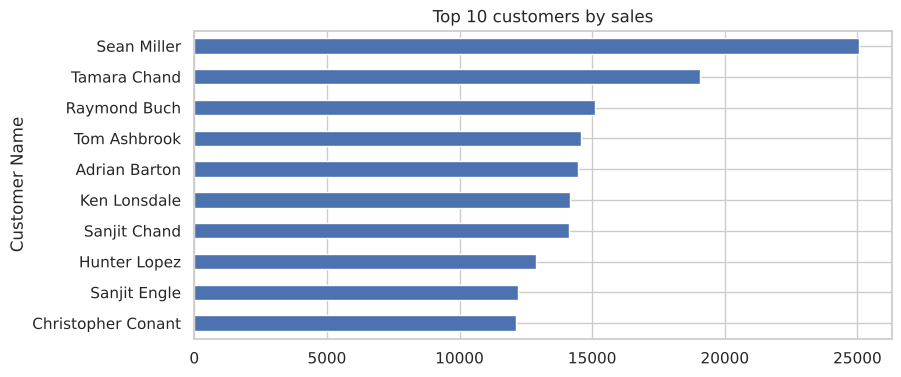

In [12]:
cust = df.groupby("Customer Name")["Sales"].sum().sort_values(ascending=False)
top20 = cust.head(int(len(cust) * 0.2)).sum() / cust.sum()
print(f"{len(cust)} customers; top 20% generate {top20:.0%} of sales")
print("Customers with 2+ orders:", f"{df.groupby('Customer ID')['Order ID'].nunique().ge(2).mean():.0%}")
cust.head(10).sort_values().plot.barh(title="Top 10 customers by sales")
plt.show()

**Finding:** the top 20% of customers generate ~48% of sales, and 98% of customers order more than once —
retention is strong, so the business is about *what is sold and at what discount*, not acquisition.

## 10. Shipping

In [13]:
print(df.groupby("Ship Mode")["ship_days"].agg(["count", "mean"]))

                count  mean
Ship Mode                  
First Class      1538  2.18
Same Day          543  0.04
Second Class     1945  3.24
Standard Class   5968  5.01


## 11. Summary & recommendations

| # | Insight | Recommendation |
|---|---------|----------------|
| 1 | $2.30M sales, $286K profit (12.5% margin); sales up ~50% from 2015 to 2018 | Growth is healthy — protect margin while scaling |
| 2 | Nov–Dec is the peak (plus September) | Stock up and staff ahead of Q4 |
| 3 | Discounts ≥30% lose money; 20% still profitable | **Cap discounts at ~20%** — biggest single profit lever |
| 4 | Tables, Bookcases, Supplies are loss-making; Furniture margin only 2.5% | Reprice or drop these lines; review supplier cost |
| 5 | Texas, Ohio, Pennsylvania lose money; Central has the lowest margin | Investigate discount/product mix in those states |
| 6 | Top 20% of customers = ~48% of sales, repeat rate is high | Loyalty/retention programme for top accounts |

**Limitations:** four years of one retailer's data; no cost or marketing breakdown; correlation is not
causation (e.g. deep discounts may be clearance of already-unprofitable items).